## Define Functions

In [1]:
from tqdm import tqdm
import numpy as np

def get_model_preds(ckpt_path, uncertainty_type, set_="test"):
    model = IrradianceEstimator.load_from_checkpoint(ckpt_path).eval()
    
    # create dictionaries to hold predictions and ground truth
    preds_test = {
        "ghi": torch.zeros(len(dataloaders[set_].dataset)),
        "kt": torch.zeros(len(dataloaders[set_].dataset))
        
    }
    trues_test = {
        "ghi": torch.zeros(len(dataloaders[set_].dataset)),
        "kt": torch.zeros(len(dataloaders[set_].dataset))
    }
    embds_ = torch.zeros((len(dataloaders[set_].dataset), model.backbone._get_final_layer_shape()))
    
    # uncertainty specific predictions
    if uncertainty_type == "gaussian":
        preds_test["ghi_var"] = torch.zeros(len(dataloaders[set_].dataset))
        preds_test["kt_var"] = torch.zeros(len(dataloaders[set_].dataset))
    elif uncertainty_type == "histloss":
        preds_test["hist_probs"] = torch.zeros((len(dataloaders[set_].dataset), model.nbins))
        preds_test["cumulative_probs"] = torch.zeros((len(dataloaders[set_].dataset), model.nbins+1))
        preds_test["bin_borders_kt"] = torch.zeros((len(dataloaders[set_].dataset), model.nbins+1))
        preds_test["bin_borders_ghi"] = torch.zeros((len(dataloaders[set_].dataset), model.nbins+1))

    # get predictions for the entire test set
    with torch.no_grad():
        for i, batch in enumerate(tqdm(dataloaders[set_])):
            for k, v in batch.items():
                batch[k] = v.to(device)
            img = batch["image"].to(device)
            
            backbone_out = model.backbone(img)
            outs_ = model.irr_head(backbone_out)
            embds_[i*64:(i+1)*64] = backbone_out.cpu()
            
            preds_ = model.get_preds(outs_, batch)
            if uncertainty_type == "gaussian":
                total_loss, pred_irr, pred_ghi, pred_var = preds_["total_loss"], preds_["target_preds"], preds_["irr_preds"], preds_["target_var"]
                pred_ghi_var = pred_var.cpu() * (batch["ghi_solis"]**2).cpu()
                preds_test["ghi_var"][64*i: 64*(i+1)] = pred_ghi_var
                preds_test["kt_var"][64*i: 64*(i+1)] = pred_var
            elif uncertainty_type == "histloss":
                total_loss, pred_irr, pred_ghi, hist_probs = preds_["total_loss"], preds_["target_preds"], preds_["irr_preds"], preds_["hist_probs"]
                cumuluative_probs = np.cumsum(torch.cat((torch.zeros((hist_probs.shape[0], 1)), hist_probs.cpu()), dim=-1).numpy(), axis=-1)
                bin_borders_kt = model.borders.cpu().permute(1, 0).repeat(batch["ghi_solis"].shape[0], 1)
                bin_borders_ghi = (model.borders.cpu() * batch["ghi_solis"].cpu()).permute(1, 0)
                preds_test["bin_borders_kt"][64*i: 64*(i+1)] = bin_borders_kt
                preds_test["bin_borders_ghi"][64*i: 64*(i+1)] = bin_borders_ghi
                preds_test["cumulative_probs"][64*i: 64*(i+1)] = torch.tensor(cumuluative_probs)
                preds_test["hist_probs"][64*i: 64*(i+1)] = hist_probs
            else:
                total_loss, pred_irr, pred_ghi = preds_["total_loss"], preds_["target_preds"], preds_["irr_preds"]
    
            preds_test["ghi"][64*i: 64*(i+1)] = pred_ghi
            preds_test["kt"][64*i: 64*(i+1)] = pred_irr
            
            trues_test["ghi"][64*i: 64*(i+1)] = batch["ghi"]
            trues_test["kt"][64*i: 64*(i+1)] = batch["ghi_kt_solis"]
    return preds_test, trues_test, embds_

In [12]:
def KNNExcessAtShortage(point_predictor, interp_shortage_thresholds, desired_shortage_freqs):
    errors = trues_test[point_predictor]["ghi"] - preds_test[point_predictor]["ghi"]
    up_samples = errors < 0
    down_samples = ~ up_samples
    
    nearest_neighbour_errors = train_errors[point_predictor][train_topk_idx[point_predictor]] # Train error distribution
    quantiles_up = torch.quantile(nearest_neighbour_errors[up_samples], torch.tensor(interp_shortage_thresholds, dtype=nearest_neighbour_errors.dtype), dim=1).abs().permute(1, 0)
    quantiles_down = torch.quantile(nearest_neighbour_errors[down_samples], torch.tensor(1 - interp_shortage_thresholds, dtype=nearest_neighbour_errors.dtype), dim=1).abs().permute(1, 0)
    
    # Quantiles are physically contrained to  >= 0
    quantiles_up, quantiles_down = quantiles_up.clamp_min(0), quantiles_down.clamp_min(0)
    
    # Compute the true and predicted required reserves
    true_req_up, true_req_down = errors[up_samples].abs()[:, None], errors[down_samples][:, None]
    pred_req_up, pred_req_down = torch.minimum(preds_test[point_predictor]["ghi"][up_samples][:, None], quantiles_up), quantiles_down
    
    # Compute excess and shortage - shortage should be almost equal to desired threshold 
    S_up, S_down = torch.nn.functional.relu(true_req_up - pred_req_up), torch.nn.functional.relu(true_req_down - pred_req_down)
    E_up, E_down = torch.nn.functional.relu(pred_req_up - true_req_up), torch.nn.functional.relu(pred_req_down - true_req_down)
    
    # Compute shortage cost
    shortage_cost = (1 - torch.tensor(desired_shortage_freqs)) / torch.tensor(desired_shortage_freqs)

    excess_up = torch.tensor(np.interp(desired_shortage_freqs, (S_up > 0).float().mean(dim=0).numpy(), (E_up.mean(dim=0) / true_req_up.mean()).numpy()))
    excess_down = torch.tensor(np.interp(desired_shortage_freqs, (S_down > 0).float().mean(dim=0).numpy(), (E_down.mean(dim=0) / true_req_down.mean()).numpy()))
    excess_shortage_up = torch.tensor(np.interp(desired_shortage_freqs, (S_up > 0).float().mean(dim=0).numpy(), E_up.mean(dim=0).numpy())) + shortage_cost * torch.tensor(np.interp(desired_shortage_freqs, (S_up > 0).float().mean(dim=0).numpy(), S_up.mean(dim=0).numpy()))
    excess_shortage_down = torch.tensor(np.interp(desired_shortage_freqs, (S_down > 0).float().mean(dim=0).numpy(), E_down.mean(dim=0).numpy())) + shortage_cost * torch.tensor(np.interp(desired_shortage_freqs, (S_down > 0).float().mean(dim=0).numpy(), S_down.mean(dim=0).numpy()))
    return {
        "excess_up": excess_up,
        "excess_down": excess_down,
        "excess+shortage_up": excess_shortage_up,
        "excess+shortage_down": excess_shortage_down,
        "shortage_freq_up": desired_shortage_freqs,
        "shortage_freq_down": desired_shortage_freqs
    }

## Load models

In [4]:
import torch
from irradiance_estimator import IrradianceEstimator
import os

root_dir = "/home/lorenzo-varaschin/solar_forecasting/mestrado_2026_2/solar-forecasting/irradiance_estimation/model_checkpoints"
uncertainty_models = {
    "gaussian_nll": os.path.join(root_dir, "uncertainty_estimation/testing_excess_metric_log/continuous_gaussianv3.ckpt"),
    "histloss_gauss": os.path.join(root_dir, "uncertainty_estimation/testing_excess_metric_log/histloss_gaussv2.ckpt")
}

# Add the additional independent models
indep_models = dict()
for k, v in uncertainty_models.items():
    indep_models[k+"-v1"] = v.replace(".ckpt", "-v1.ckpt")
    indep_models[k+"-v2"] = v.replace(".ckpt", "-v2.ckpt")
uncertainty_models.update(indep_models)

## Load dataloaders

In [5]:
from omegaconf import OmegaConf
from utils import create_dataloaders
from torch.utils.data import DataLoader

device = "cuda:0"

config = OmegaConf.load("configs/config.yaml")
dataloaders = create_dataloaders(config)

In [6]:
import h5py
# to compute the variance for selective prediction ranking
with h5py.File(dataloaders["test"].dataset.hdf5_path, 'r') as f:
    test_set = f["test"]
    idxs = test_set["sample_idxs"][:]
    ghi_solis = test_set["GHI/clear_sky"][idxs]

## Get model predictions

In [7]:
preds_test, trues_test, img_embds = dict(), dict(), dict()

# uncertainty aware models
for head_name, irr_head in uncertainty_models.items():
    print(head_name)
    preds_, trues_, embds_ = get_model_preds(irr_head, head_name.split("_")[0])
    preds_test[head_name] = preds_
    trues_test[head_name] = trues_
    img_embds[head_name] = embds_

gaussian_nll


100%|█████████████████████████████████████████████████████████████████████████████████| 781/781 [00:15<00:00, 48.92it/s]


histloss_gauss


100%|█████████████████████████████████████████████████████████████████████████████████| 781/781 [00:15<00:00, 49.32it/s]


gaussian_nll-v1


...

100%|█████████████████████████████████████████████████████████████████████████████████| 781/781 [00:15<00:00, 50.10it/s]


histloss_gauss-v1


100%|█████████████████████████████████████████████████████████████████████████████████| 781/781 [00:16<00:00, 48.75it/s]


histloss_gauss-v2


100%|█████████████████████████████████████████████████████████████████████████████████| 781/781 [00:16<00:00, 48.47it/s]


In [8]:
# compute distances for KNN baseline
train_errors, train_topk_idx = dict(), dict()

# compute train distances in batches
batch_size = 10000

# uncertainty aware models
for head_name, irr_head in uncertainty_models.items():
    print(head_name)
    train_preds_, train_trues_, train_embds = get_model_preds(irr_head, head_name.split("_")[0], set_="train")
    train_topk_idx[head_name] = torch.zeros((len(img_embds[head_name]), 2000), dtype=torch.int64)
    for i in tqdm(range((len(img_embds[head_name]) // batch_size) + 1)):
        distances_ = torch.cdist(img_embds[head_name][i*batch_size:(i+1)*batch_size].cuda(), train_embds.cuda()).cpu()
        train_topk_idx[head_name][i*batch_size:(i+1)*batch_size] = torch.topk(distances_, k=2000, dim=1, largest=False).indices
    train_errors[head_name] = train_trues_["ghi"] - train_preds_["ghi"]

gaussian_nll


100%|█████████████████████████████████████████████████████████████████████████████████████| 5/5 [00:25<00:00,  5.04s/it]


histloss_gauss


100%|█████████████████████████████████████████████████████████████████████████████████████| 5/5 [00:25<00:00,  5.13s/it]


gaussian_nll-v1


...

100%|█████████████████████████████████████████████████████████████████████████████████████| 5/5 [00:25<00:00,  5.09s/it]


histloss_gauss-v1


100%|█████████████████████████████████████████████████████████████████████████████████████| 5/5 [00:25<00:00,  5.07s/it]


histloss_gauss-v2


100%|█████████████████████████████████████████████████████████████████████████████████████| 5/5 [00:25<00:00,  5.12s/it]


## Compute point prediction metrics

In [9]:
def get_hist_quantiles(cp, bb, qs):
    qs = np.atleast_1d(qs)
    N, K = cp.shape
    out = np.empty((N, len(qs)))
    rows = np.arange(N)
    for j, q in enumerate(qs):                      
        idx = (cp < q).sum(axis=1)                  
        idx = np.clip(idx, 1, K - 1)
        x0, x1 = cp[rows, idx - 1], cp[rows, idx]
        y0, y1 = bb[rows, idx - 1], bb[rows, idx]
        out[:, j] = y0 + ((q-x0) / (x1-x0)) * (y1 - y0)
    return out
    
rmse_, mae_ = dict(), dict()
for point_predictor in ["gaussian_nll", "histloss_gauss"]:
    for i in range(3):
        if i == 0:
            rmse_[point_predictor] = ((preds_test[point_predictor]["ghi"] - trues_test[point_predictor]["ghi"])**2).mean().sqrt().item() / 3
            if "histloss" in point_predictor:
                # for hist losses median is different than mean, so use median to compute MAE
                hist_preds = get_hist_quantiles(preds_test[point_predictor]["cumulative_probs"], preds_test[point_predictor]["bin_borders_ghi"], np.array([0.5]))
                mae_[point_predictor] = ((torch.tensor(hist_preds).view(-1) - trues_test[point_predictor]["ghi"]).abs()).mean().item() / 3
            else:
                mae_[point_predictor] = ((preds_test[point_predictor]["ghi"] - trues_test[point_predictor]["ghi"]).abs()).mean().item() / 3
        else:
            pp = point_predictor + f"-v{i}"
            rmse_[point_predictor] += ((preds_test[pp]["ghi"] - trues_test[pp]["ghi"])**2).mean().sqrt().item() / 3
            if "histloss" in pp:
                # for hist losses median is different than mean, so use median to compute MAE
                hist_preds = get_hist_quantiles(preds_test[pp]["cumulative_probs"], preds_test[pp]["bin_borders_ghi"], np.array([0.5]))
                mae_[point_predictor] += ((torch.tensor(hist_preds).view(-1) - trues_test[pp]["ghi"]).abs()).mean().item() / 3
            else:
                mae_[point_predictor] += ((preds_test[pp]["ghi"] - trues_test[pp]["ghi"]).abs()).mean().item() / 3

/tmp/ipykernel_906649/3686278985.py:11: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments. To learn more, see the migration guide https://numpy.org/devdocs/numpy_2_0_migration_guide.html#adapting-to-changes-in-the-copy-keyword
  out[:, j] = y0 + ((q-x0) / (x1-x0)) * (y1 - y0)


## Compute uncertainty metrics

In [10]:
from metrics import ExcessAtShortage

shortage_thresholds = np.linspace(0.5, 10, 20) / 100
metrics_ = {
    "gaussian_nll": ExcessAtShortage(thresholds=shortage_thresholds, uncertainty_type="gaussian"),
    "histloss_gauss": ExcessAtShortage(thresholds=shortage_thresholds, uncertainty_type="histogram")
}

In [13]:
excess, excess_shortage = dict(), dict()
for point_predictor in ["gaussian_nll", "histloss_gauss"]:
    excess[point_predictor], excess_shortage[point_predictor] = dict(), dict()
    for uncertainty_estimator in ["gaussian_nll", "histloss_gauss", "knn_error"]:
        for i in range(3):
            if i == 0:
                if uncertainty_estimator == "knn_error":
                    results_ = KNNExcessAtShortage(
                        point_predictor=point_predictor,
                        interp_shortage_thresholds=np.linspace(1e-4, 10, 201) / 100,
                        desired_shortage_freqs=shortage_thresholds
                    )
                else:
                    results_ = metrics_[uncertainty_estimator](
                        trues = trues_test[point_predictor],
                        preds_point = preds_test[point_predictor],
                        preds_uncertainty = preds_test[uncertainty_estimator]
                    )
                excess[point_predictor][uncertainty_estimator] = {
                    "up": results_["excess_up"] / 3,
                    "down": results_["excess_down"] / 3,
                }
                excess_shortage[point_predictor][uncertainty_estimator] = {
                    "up": results_["excess+shortage_up"] / 3,
                    "down": results_["excess+shortage_down"] / 3,
                }
            else:
                if uncertainty_estimator == "knn_error":
                    results_ = KNNExcessAtShortage(
                        point_predictor=point_predictor+f"-v{i}",
                        interp_shortage_thresholds=np.linspace(1e-4, 10, 201) / 100,
                        desired_shortage_freqs=shortage_thresholds
                    )
                else:
                    results_ = metrics_[uncertainty_estimator](
                        trues = trues_test[point_predictor+f"-v{i}"],
                        preds_point = preds_test[point_predictor+f"-v{i}"],
                        preds_uncertainty = preds_test[uncertainty_estimator+f"-v{i}"]
                    )
                excess[point_predictor][uncertainty_estimator]["up"] += results_["excess_up"] / 3
                excess[point_predictor][uncertainty_estimator]["down"] += results_["excess_down"] / 3
                excess_shortage[point_predictor][uncertainty_estimator]["up"] += results_["excess+shortage_up"] / 3
                excess_shortage[point_predictor][uncertainty_estimator]["down"] += results_["excess+shortage_down"] / 3

In [25]:
import matplotlib.pyplot as plt
from prettytable import PrettyTable

def plot_excess_shortage_metrics(point_predictor, direction):
    fig, ax = plt.subplots(1, 2, figsize=(10, 5), layout="constrained")
    
    ax[0].plot(shortage_thresholds, excess[point_predictor]["gaussian_nll"][direction], label="GaussianNLLL", marker=".")
    ax[0].plot(shortage_thresholds, excess[point_predictor]["histloss_gauss"][direction], label="HistlossGauss", marker=".")
    ax[0].plot(shortage_thresholds, excess[point_predictor]["knn_error"][direction], label="KNN Error (baseline)", marker=".")
    ax[0].grid(True)
    ax[0].set_xticks(np.linspace(0.01, 0.1, 10))
    ax[0].set_title(f"Excess@Shortage - {point_predictor} point predictor")
    ax[0].set_xlabel("Shortage Frequency")
    ax[0].legend()
    
    ax[1].plot(shortage_thresholds, excess_shortage[point_predictor]["gaussian_nll"][direction], label="GaussianNLLL", marker=".")
    ax[1].plot(shortage_thresholds, excess_shortage[point_predictor]["histloss_gauss"][direction], label="HistlossGauss", marker=".")
    ax[1].plot(shortage_thresholds, excess_shortage[point_predictor]["knn_error"][direction], label="KNN Error (baseline)", marker=".")
    ax[1].grid(True)
    ax[1].set_xticks(np.linspace(0.01, 0.1, 10))
    ax[1].set_title(f"Excess+Shortage - {point_predictor} point predictor")
    ax[1].set_xlabel("Shortage Frequency")
    ax[1].legend()
    
    idx_ = np.where(shortage_thresholds==0.05)[0].item()
    table_cols = [" ", "Mean", "Median", "GaussianNLL (Point Predictor)", "HLGauss (Point Predictor)"]
    table = PrettyTable(table_cols)
    table_row = ["Model (Uncertainty Estimator)", "RMSE", "MAE", f"Excess@0.05 ({direction})", f"Excess@0.05 ({direction})"]
    table.add_row(table_row, divider=True)
    table_row = [
        "GaussianNLL",
        f"{rmse_["gaussian_nll"]:.2f}",
        f"{mae_["gaussian_nll"]:.2f}",
        f"{excess['gaussian_nll']['gaussian_nll'][direction][idx_]:.3f}",
        f"{excess['histloss_gauss']['gaussian_nll'][direction][idx_]:.3f}"
    ]
    table.add_row(table_row)
    table_row = [
        "HLGauss",
        f"{rmse_["histloss_gauss"]:.2f}",
        f"{mae_["histloss_gauss"]:.2f}",
        f"{excess['gaussian_nll']['histloss_gauss'][direction][idx_]:.3f}",
        f"{excess['histloss_gauss']['histloss_gauss'][direction][idx_]:.3f}"
    ]
    table.add_row(table_row)
    table_row = [
        "KNN Error (baseline)",
        "-",
        "-",
        f"{excess['gaussian_nll']['knn_error'][direction][idx_]:.3f}",
        f"{excess['histloss_gauss']['knn_error'][direction][idx_]:.3f}"
    ]
    table.add_row(table_row)
    print(table)

+-------------------------------+-------+--------+-------------------------------+---------------------------+
|                               |  Mean | Median | GaussianNLL (Point Predictor) | HLGauss (Point Predictor) |
+-------------------------------+-------+--------+-------------------------------+---------------------------+
| Model (Uncertainty Estimator) |  RMSE |  MAE   |        Excess@0.05 (up)       |      Excess@0.05 (up)     |
+-------------------------------+-------+--------+-------------------------------+---------------------------+
|          GaussianNLL          | 38.77 | 21.78  |             2.367             |           2.332           |
|            HLGauss            | 38.93 | 21.70  |             1.693             |           1.572           |
|      KNN Error (baseline)     |   -   |   -    |             2.357             |           2.545           |
+-------------------------------+-------+--------+-------------------------------+---------------------------+


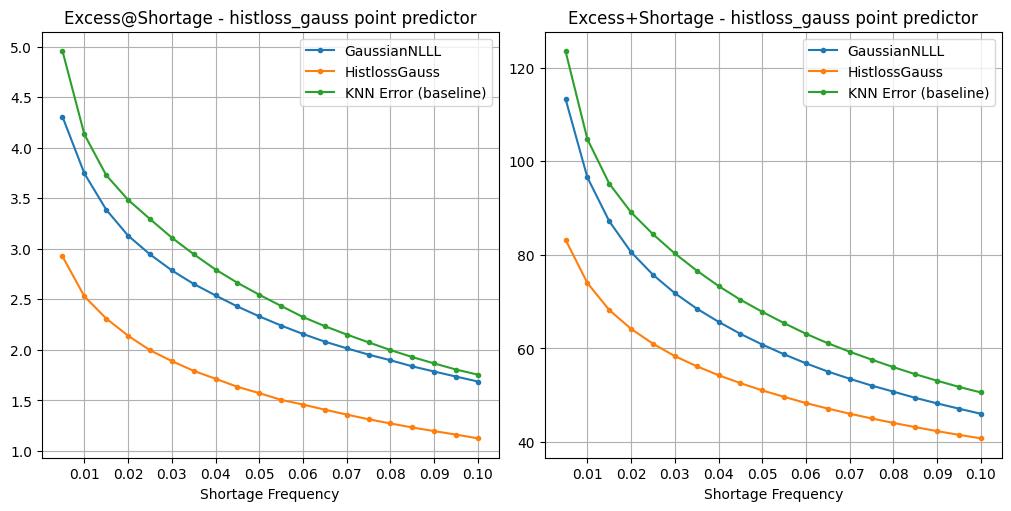

In [26]:
plot_excess_shortage_metrics("histloss_gauss", "up")